<a href="https://colab.research.google.com/github/ennaguiyoussef/SRGAN-Image-Super-Resolution/blob/main/notebooks/04a_generator_pretraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 4A — Generator Pretraining with MSE
**Goal:** teach the generator to reconstruct HR pixels before adversarial training.

The discriminator and VGG are not used. This is a first learning/pipeline experiment, not a reproduction of the paper's full training schedule.

**Default:** 100 training images, 50 validation images, 20 total epochs, batch size 16, Adam at 1e-4, float32. One random crop is sampled per training image per epoch: this is only 140 optimizer steps. More data and iterations will be needed for a useful final model.

Use a T4 GPU runtime. Budget approximately 5–20 minutes for a first pilot including restoring images; actual time depends on Colab and Drive. Read the measured epoch duration to estimate remaining training time.


## 1. Update the project
The cell fast-forwards an existing clean main checkout. Local tracked edits are preserved: if present, the update stops instead of discarding them.


In [2]:
from pathlib import Path
import importlib
import json
import os
import subprocess
import sys

PROJECT_ROOT = Path("/content/SRGAN-Image-Super-Resolution")
REPO_URL = "https://github.com/ennaguiyoussef/SRGAN-Image-Super-Resolution.git"
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    if not (PROJECT_ROOT / ".git").is_dir():
        raise RuntimeError("Project folder exists but is not a Git checkout.")
    changes = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "status", "--porcelain", "--untracked-files=no"],
        text=True,
    )
    if changes.strip():
        raise RuntimeError("Save local tracked edits before updating this checkout.")
    branch = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "branch", "--show-current"], text=True
    ).strip()
    if branch != "main":
        raise RuntimeError("Select the main branch before running this notebook.")
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "origin", "main"], check=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
importlib.invalidate_caches()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("Project checkout ready.")


Project checkout ready.


## 2. Read settings and verify the GPU
An **epoch** is one pass through the selected training images. Each epoch samples fresh random HR crops.

MSE compares generated SR with HR in **[-1, 1]**. A smaller value means closer pixels. We minimize it with backpropagation and Adam.

Keep the defaults for the first run. `epochs` is the **total target**, not additional epochs on resume. Increase it to continue the same experiment. Changes to batch size, learning rate, data subset, or seed require a new run name.


In [3]:
import yaml
import torch
from src.setup import environment_report, load_config, seed_everything

config = load_config(PROJECT_ROOT / "configs/srgan.yaml")
pretrain = yaml.safe_load((PROJECT_ROOT / "configs/pretrain.yaml").read_text())
if pretrain["num_workers"] != 0:
    raise ValueError("This phase uses num_workers=0 for epoch-boundary replay.")
report = environment_report()
print(json.dumps(report, indent=2))
if not report["cuda_available"]:
    raise RuntimeError("Select a GPU runtime before training.")
device = torch.device("cuda:0")
seed_everything(config["seed"])
print(json.dumps(pretrain, indent=2))


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "cuda_runtime": "13.0",
  "cuda_available": true,
  "gpu": "Tesla T4"
}
{
  "smoke_mode": true,
  "epochs": 20,
  "learning_rate": 0.0001,
  "batch_size": 16,
  "gradient_clip_norm": 1.0,
  "num_workers": 0,
  "run_name": "pretrain_smoke_v1",
  "resume": true
}


## 3. Mount Drive and restore only the images needed
Phase 2 must already have saved the manifest and the full HR archive cache. The notebook reuses local images and extracts missing selected images from Drive after a runtime reset. No held-out test images are read.


In [4]:
from google.colab import drive
from src.setup import prepare_directories
from src.data import extract_hr_archive, split_manifest
from src.dataset import SuperResolutionDataset

drive.mount("/content/drive")
OUTPUT_ROOT = Path("/content/drive/MyDrive/SRGAN-Image-Super-Resolution")
paths = prepare_directories(PROJECT_ROOT, OUTPUT_ROOT)
DATA_ROOT = paths["data"] / "DIV2K"
manifest_path = OUTPUT_ROOT / "splits" / "div2k_seed42.json"
if not manifest_path.is_file():
    raise RuntimeError("Complete phase 2 first: split manifest is missing.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
if manifest != split_manifest(config["seed"]):
    raise RuntimeError("Split manifest does not match the current seed.")
train_names = manifest["train_smoke"] if pretrain["smoke_mode"] else manifest["train"]
validation_names = manifest["validation"]
for folder, names in [("DIV2K_train_HR", train_names), ("DIV2K_valid_HR", validation_names)]:
    missing = [name for name in names if not (DATA_ROOT / name).is_file()]
    if missing:
        archive = OUTPUT_ROOT / "dataset_cache" / f"{folder}.zip"
        if not archive.is_file():
            raise RuntimeError(f"Missing archive {archive.name}. Complete phase 2 first.")
        extract_hr_archive(archive, DATA_ROOT, folder, [int(Path(name).stem) for name in missing])

train_dataset = SuperResolutionDataset(
    DATA_ROOT, train_names, hr_size=config["hr_crop_size"], scale=config["scale_factor"], training=True,
)
validation_dataset = SuperResolutionDataset(
    DATA_ROOT, validation_names, hr_size=config["hr_crop_size"], scale=config["scale_factor"], training=False,
)
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Held-out test images are not loaded.")


Mounted at /content/drive
Training images: 100
Validation images: 50
Held-out test images are not loaded.


## 4. Initialize the generator and identify the experiment
The initial preview below uses fresh random weights. If resuming, training will subsequently load `last.pt`.

Each run has a separate Drive directory. `last.pt` contains the latest model, Adam state, history, settings, and best validation weights. `best_generator.pt` exports the best weights for later use.

Resume is at **epoch boundaries**: if Colab stops midway through an epoch, that partial epoch is repeated. The code uses epoch-based random seeds and zero workers. Exact numeric replay is not guaranteed across different devices or PyTorch versions.


In [5]:
import hashlib
import re
from src.models import Generator

if not re.fullmatch(r"[A-Za-z0-9_-]+", pretrain["run_name"]):
    raise ValueError("run_name must contain only letters, numbers, underscores, or hyphens.")
mode_name = "smoke100" if pretrain["smoke_mode"] else "full800"
RUN_ID = f"{pretrain['run_name']}_{mode_name}"
RUN_DIR = paths["checkpoints"] / RUN_ID
RESULTS_DIR = paths["results"] / RUN_ID
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(config["seed"])
generator = Generator().to(device).eval()
preview_pairs = [validation_dataset[i] for i in range(3)]
preview_lr = torch.stack([pair[0] for pair in preview_pairs]).to(device)
with torch.inference_mode():
    initial_sr = generator(preview_lr).cpu()
experiment = {
    "phase": "4A", "generator": "Generator(16 residual blocks, 64 channels)",
    "scale_factor": config["scale_factor"], "hr_crop_size": config["hr_crop_size"],
    "manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "train_names": train_names, "validation_names": validation_names,
    "degradation": "Pillow bicubic after HR crop", "lr_range": [0, 1], "hr_range": [-1, 1],
}
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print("Run directory:", RUN_DIR)
print("Resume checkpoint exists:", (RUN_DIR / "last.pt").is_file())


Run directory: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/checkpoints/pretrain_smoke_v1_smoke100
Resume checkpoint exists: True


## 5. Train the generator
For each batch: **LR → generator → SR → MSE(SR, HR) → backward → Adam step**.

Validation runs in `eval()` mode without gradients. The best checkpoint is selected by validation MSE, never by test results. Gradients are clipped to norm 1.0. Training uses float32; mixed precision is deferred.

Checkpoints are written via a temporary file after each complete epoch. Drive must finish writing before a saved epoch can be relied on. Rerun the notebook with the same settings to resume. If epoch 20 is already saved, this cell does not train another 20 epochs.


In [6]:
pretrain["epochs"] = 100

In [7]:
from src.pretrain import fit_pretrain

state = fit_pretrain(
    generator, train_dataset, validation_dataset, RUN_DIR,
    epochs=pretrain["epochs"], batch_size=pretrain["batch_size"],
    learning_rate=pretrain["learning_rate"], seed=config["seed"],
    gradient_clip_norm=pretrain["gradient_clip_norm"],
    device=device, resume=pretrain["resume"],
    experiment=experiment, source_commit=commit,
)
print("Completed epoch:", state["epoch"])
print("Best validation epoch:", state["best_epoch"])
print("Best validation MSE:", state["best_val_mse"])
if state["best_epoch"] == 0:
    print("No trained epoch improved validation over the untrained baseline. Inspect before proceeding.")


Resuming after epoch 20; target total epochs: 100


Epoch 21/100:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 021/100: train MSE=0.047004, val MSE=0.058632, RGB PSNR=19.66 dB, time=17.2s; saved


Epoch 22/100:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 022/100: train MSE=0.043593, val MSE=0.051619, RGB PSNR=20.22 dB, time=16.2s; saved


Epoch 23/100:   0%|          | 0/7 [00:00<?, ?it/s]

... (151 outputs left out)

Epoch 99/100:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 099/100: train MSE=0.025382, val MSE=0.033204, RGB PSNR=22.60 dB, time=18.0s; saved


Epoch 100/100:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 100/100: train MSE=0.027075, val MSE=0.029843, RGB PSNR=23.41 dB, time=17.0s; saved
Completed epoch: 100
Best validation epoch: 100
Best validation MSE: 0.029843037873506548


## 6. Plot learning curves
Training MSE uses random crops in training mode; validation MSE uses fixed center crops in evaluation mode. They need not match, and validation need not improve every epoch.

Validation PSNR is the **mean per-image RGB PSNR**, computed after mapping the error to [0, 1], without border shaving. These center-crop measurements are for this experiment, not official benchmark scores.


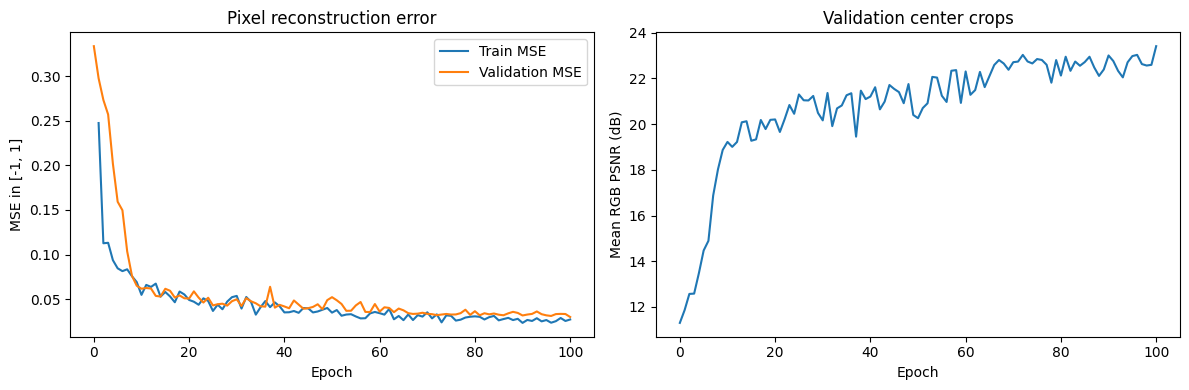

In [8]:
import matplotlib.pyplot as plt

history = state["history"]
trained = [row for row in history if row["train_mse"] is not None]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([r["epoch"] for r in trained], [r["train_mse"] for r in trained], label="Train MSE")
axes[0].plot([r["epoch"] for r in history], [r["val_mse"] for r in history], label="Validation MSE")
axes[0].set(xlabel="Epoch", ylabel="MSE in [-1, 1]", title="Pixel reconstruction error")
axes[0].legend()
axes[1].plot([r["epoch"] for r in history], [r["val_psnr_rgb"] for r in history])
axes[1].set(xlabel="Epoch", ylabel="Mean RGB PSNR (dB)", title="Validation center crops")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pretrain_learning_curves.png", dpi=160)
plt.show()


## 7. Compare fresh random weights, the best generator, and bicubic
All examples come from the same validation crops. Bicubic is a baseline, not a learned model. The pilot generator is not guaranteed to outperform it. HR is the reference, not a generated result.


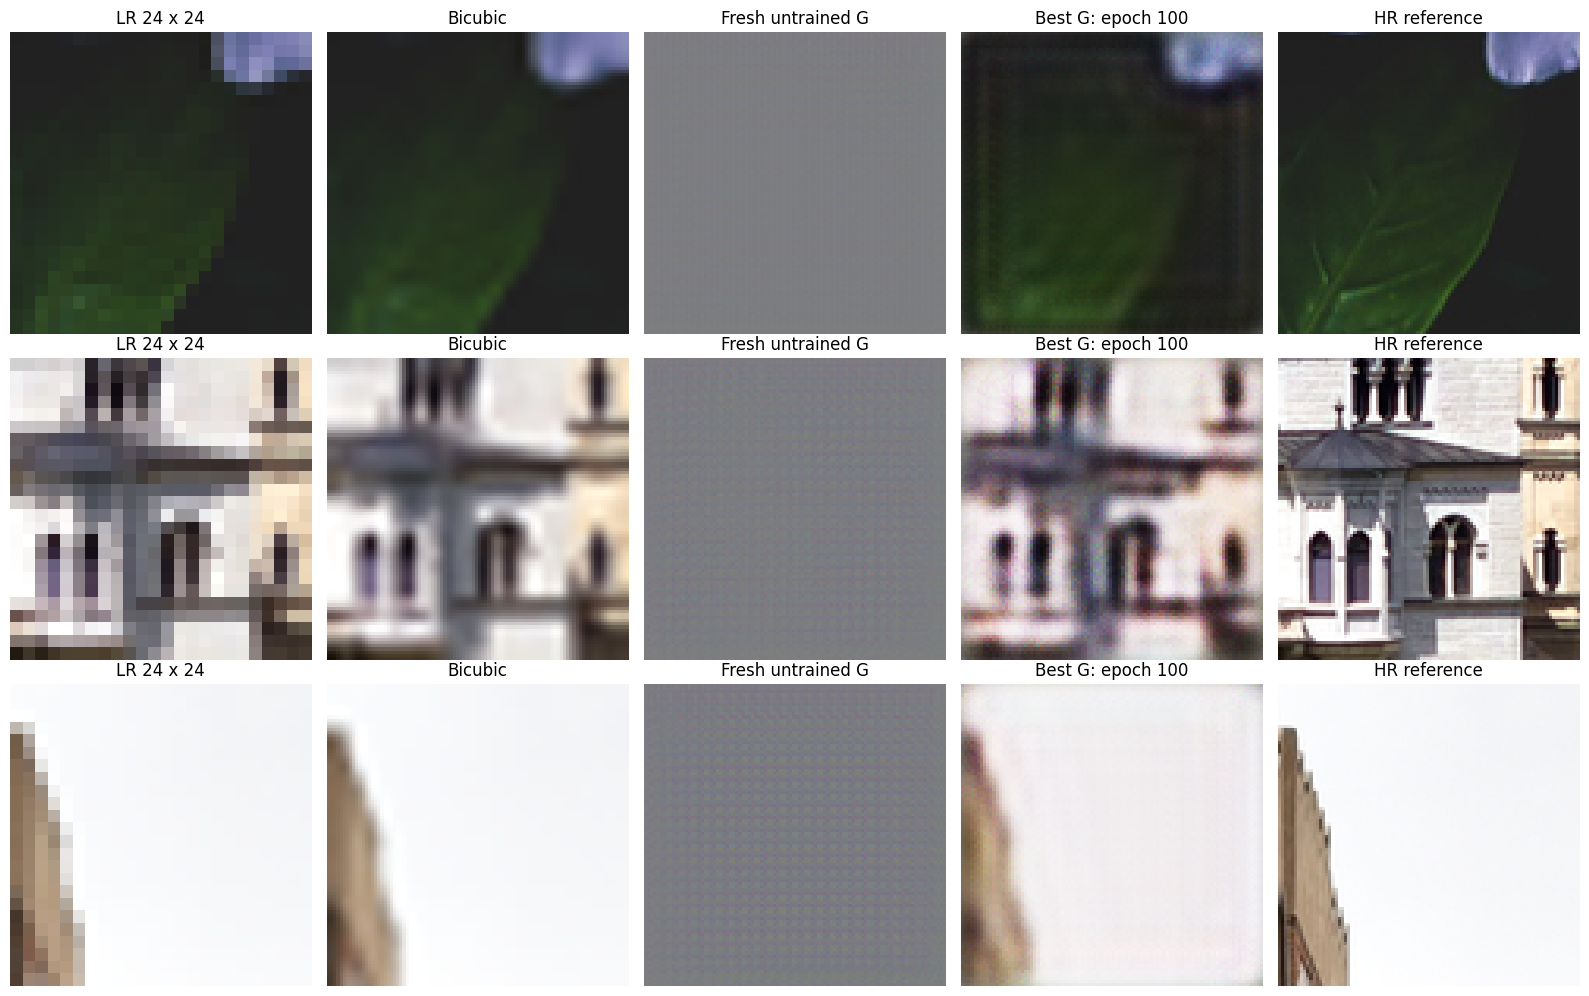

Bicubic: MSE=0.023353, RGB PSNR=26.01 dB
Best G:  MSE=0.029843, RGB PSNR=23.41 dB


In [9]:
import numpy as np
from PIL import Image
from src.pretrain import validate
from torch.utils.data import DataLoader

generator.load_state_dict(state["best_model"])
generator.eval()
with torch.inference_mode():
    best_sr = generator(preview_lr).cpu()

def rgb_image(tensor):
    return ((tensor + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for row, (lr, hr) in enumerate(preview_pairs):
    lr_image = lr.permute(1, 2, 0).numpy()
    bicubic = Image.fromarray(np.rint(lr_image * 255).astype(np.uint8)).resize(
        (96, 96), Image.Resampling.BICUBIC
    )
    panels = [
        (lr_image, "LR 24 x 24"), (bicubic, "Bicubic"),
        (rgb_image(initial_sr[row]), "Fresh untrained G"),
        (rgb_image(best_sr[row]), f"Best G: epoch {state['best_epoch']}"),
        (rgb_image(hr), "HR reference"),
    ]
    for col, (image, title) in enumerate(panels):
        axes[row, col].imshow(image, interpolation="nearest")
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pretrain_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Same 50 validation crops and Pillow bicubic policy as the visual baseline.
bicubic_mses, bicubic_psnrs = [], []
for lr, hr in validation_dataset:
    array = np.rint(lr.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    baseline = Image.fromarray(array).resize((96, 96), Image.Resampling.BICUBIC)
    baseline_tensor = torch.from_numpy(np.array(baseline, dtype=np.float32).transpose(2, 0, 1).copy()) / 255
    target = (hr + 1) / 2
    mse01 = (baseline_tensor - target).square().mean().item()
    bicubic_mses.append(mse01 * 4)
    bicubic_psnrs.append(-10 * np.log10(max(mse01, 1e-12)))
best_metrics = validate(
    generator, DataLoader(validation_dataset, batch_size=pretrain["batch_size"], num_workers=0), device
)
print(f"Bicubic: MSE={np.mean(bicubic_mses):.6f}, RGB PSNR={np.mean(bicubic_psnrs):.2f} dB")
print(f"Best G:  MSE={best_metrics['val_mse']:.6f}, RGB PSNR={best_metrics['val_psnr_rgb']:.2f} dB")


## 8. Save the pilot report
Share the learning curves, comparison, and final printed metrics before starting adversarial training. Completing this notebook confirms the pilot run finished, not that the model has converged.


In [10]:
from src.pretrain import atomic_json_save

report.update({
    "git_commit": commit, "run_id": RUN_ID, "pretrain_settings": pretrain,
    "completed_epoch": state["epoch"], "best_epoch": state["best_epoch"],
    "untrained_validation": state["history"][0],
    "best_generator_validation": best_metrics,
    "bicubic_validation": {
        "val_mse": float(np.mean(bicubic_mses)),
        "val_psnr_rgb": float(np.mean(bicubic_psnrs)),
    },
    "validation_protocol": "50 fixed RGB 96x96 center crops; no border shave; mean per-image PSNR",
    "checkpoint": str(RUN_DIR / "last.pt"),
    "best_weights": str(RUN_DIR / "best_generator.pt"),
    "test_used": False,
})
atomic_json_save(report, RESULTS_DIR / "pretrain_report.json")
print("Phase 4A pilot complete: generator pretraining, validation, and checkpoints saved.")
print("Results:", RESULTS_DIR)
print("Next: inspect curves and images before choosing a longer run or phase 4B.")


Phase 4A pilot complete: generator pretraining, validation, and checkpoints saved.
Results: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/results/pretrain_smoke_v1_smoke100
Next: inspect curves and images before choosing a longer run or phase 4B.
